# Customer Churn Prediction & Explainable AI

**Goal:** predict which telecom customers are likely to leave (churn), explain *why* with SHAP, and turn the model into concrete retention actions.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns, ~26.5% churn).

**What this notebook does**

1. Load, inspect and clean the data
2. Exploratory data analysis (univariate -> bivariate -> multivariate)
3. Leak-free preprocessing with a scikit-learn `Pipeline`
4. Model comparison with 5-fold cross-validation + light hyper-parameter tuning
5. One-time evaluation on a held-out test set
6. Business-driven decision-threshold selection (done on training data only)
7. Explainability with SHAP (global + individual customers)
8. Business recommendations, model export

> **Rule used throughout:** the test set is touched only for the final report. Every choice (model, hyper-parameters, threshold) is made on training data via cross-validation.

## Business understanding

**Business problem.** A telecom operator loses about 1 in 4 customers (26.5% churn in this dataset). Winning a new customer typically costs more than keeping an existing one, so unmanaged churn directly erodes revenue and acquisition efficiency.

**Decision this analysis supports.** *Which customers should the retention team contact this month, with which offer, and is it worth the cost?*

| Business question | Answer in this notebook |
|---|---|
| Who is churning? | Section 4 (segments in 4.6) |
| Who is likely to churn next? | Sections 7-9 (model, ROC-AUC 0.84) |
| How many customers should we contact? | Section 10 (cost-based threshold, lift table) |
| Why does a customer look risky? | Section 11 (SHAP) |
| What should we do about it? | Sections 12-13 |

**Success measures.** Share of churners reached by the campaign (recall), cost-efficiency of the offers (precision, expected value) and, after launch, the retention uplift measured with an A/B test.

The full business report (problem, feasibility, financial logic, risks, roadmap) is in [`reports/Business_Report.md`](../reports/Business_Report.md).

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    make_scorer, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for folder in (FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)
print("Data file:", DATA_PATH.relative_to(ROOT))

scikit-learn: 1.8.0 | pandas: 3.0.2 | numpy: 2.4.4
Data file: data/raw/Telco-Customer-Churn.csv


## 2. Data loading & inspection

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print("\nMissing values per column (NaN):")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none")

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as text (`object`/`str`) even though it should be numeric, and `.info()` shows no NaN. That means the missing values are hidden as **blank strings**. This is the one real data-quality problem in this dataset.

## 3. Data cleaning

In [4]:
df_clean = df.copy()

# 1) TotalCharges: hidden blanks -> numeric
blank = df_clean["TotalCharges"].astype(str).str.strip().eq("")
print("Blank TotalCharges strings:", blank.sum())
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")

missing_tc = df_clean["TotalCharges"].isna()
display(df_clean.loc[missing_tc, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# Every blank belongs to a customer with tenure == 0 (brand-new, not billed yet) -> 0 is the logical value
assert (df_clean.loc[missing_tc, "tenure"] == 0).all()
df_clean.loc[missing_tc, "TotalCharges"] = 0.0

# 2) Duplicates and ID uniqueness
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())

# 3) Target encoding + sanity checks
df_clean["ChurnFlag"] = (df_clean["Churn"] == "Yes").astype(int)
assert df_clean["SeniorCitizen"].isin([0, 1]).all()
assert df_clean["Churn"].isin(["Yes", "No"]).all()

print("\nMissing values after cleaning:", int(df_clean.isna().sum().sum()))
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print(f"Overall churn rate: {df_clean['ChurnFlag'].mean():.2%}")

Blank TotalCharges strings: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Duplicate rows: 0
Duplicate customer IDs: 0

Missing values after cleaning: 0
TotalCharges dtype: float64
Overall churn rate: 26.54%


### Feature groups
Defined **explicitly** (not with `select_dtypes`) so the notebook behaves identically across pandas versions and the lists are documented in one place.

In [5]:
TARGET = "ChurnFlag"
ID_COL = "customerID"

NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
BINARY = ["SeniorCitizen"]          # already 0/1 -> no scaling or encoding needed
CATEGORICAL = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]
FEATURES = NUMERIC + BINARY + CATEGORICAL

# Safety check: every column is either a feature, the target, or the ID
unused = set(df_clean.columns) - set(FEATURES) - {TARGET, ID_COL, "Churn"}
assert not unused, f"Columns not assigned to any group: {unused}"
print(len(NUMERIC), "numeric |", len(BINARY), "binary |", len(CATEGORICAL), "categorical ->", len(FEATURES), "features")

3 numeric | 1 binary | 15 categorical -> 19 features


## 4. Exploratory Data Analysis

EDA is done on the full cleaned data **only to understand it** (no statistics from here are fed into the model).

### 4.1 Target distribution

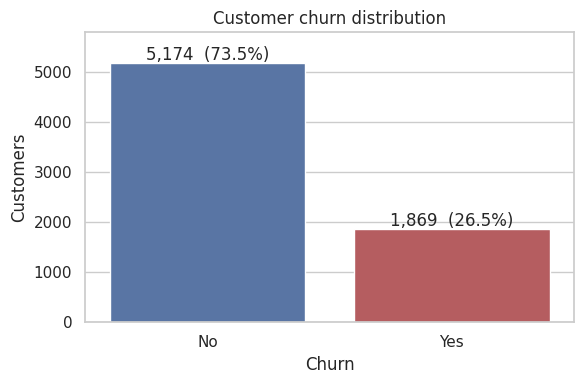

Majority-class baseline accuracy: 73.46%  <- any model must beat this


In [6]:
counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + 60, f"{c:,}  ({p:.1f}%)", ha="center")
ax.set(title="Customer churn distribution", xlabel="Churn", ylabel="Customers", ylim=(0, counts.max() * 1.12))
plt.tight_layout(); save_fig("01_churn_distribution.png"); plt.show()

print(f"Majority-class baseline accuracy: {counts.max() / counts.sum():.2%}  <- any model must beat this")

The data is **imbalanced** (about 1 churner for every 3 loyal customers). Accuracy alone is therefore misleading, so we track **ROC-AUC, PR-AUC, precision, recall and F1**.

### 4.2 Univariate analysis - numeric features

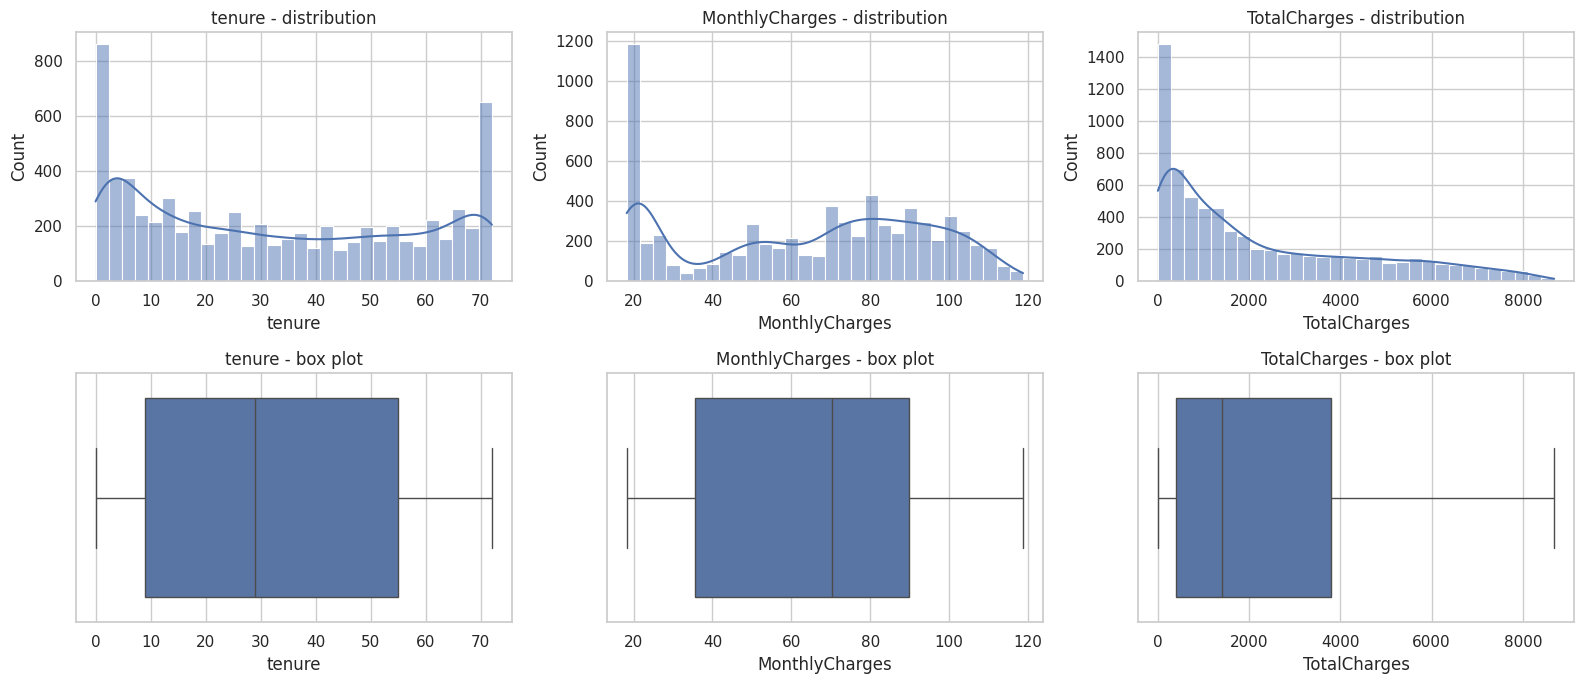

,count,mean,std,min,25%,50%,75%,max,skew
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80,0.96


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, col in enumerate(NUMERIC):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=axes[0, j])
    axes[0, j].set_title(f"{col} - distribution")
    sns.boxplot(x=df_clean[col], ax=axes[1, j])
    axes[1, j].set_title(f"{col} - box plot")
plt.tight_layout(); save_fig("02_numeric_univariate.png"); plt.show()

summary = df_clean[NUMERIC].describe().T
summary["skew"] = df_clean[NUMERIC].skew()
display(summary.round(2))

`tenure` is bimodal (many brand-new customers and many long-term ones), `TotalCharges` is right-skewed, and there are no extreme outliers that need removal.

### 4.3 Univariate analysis - categorical features

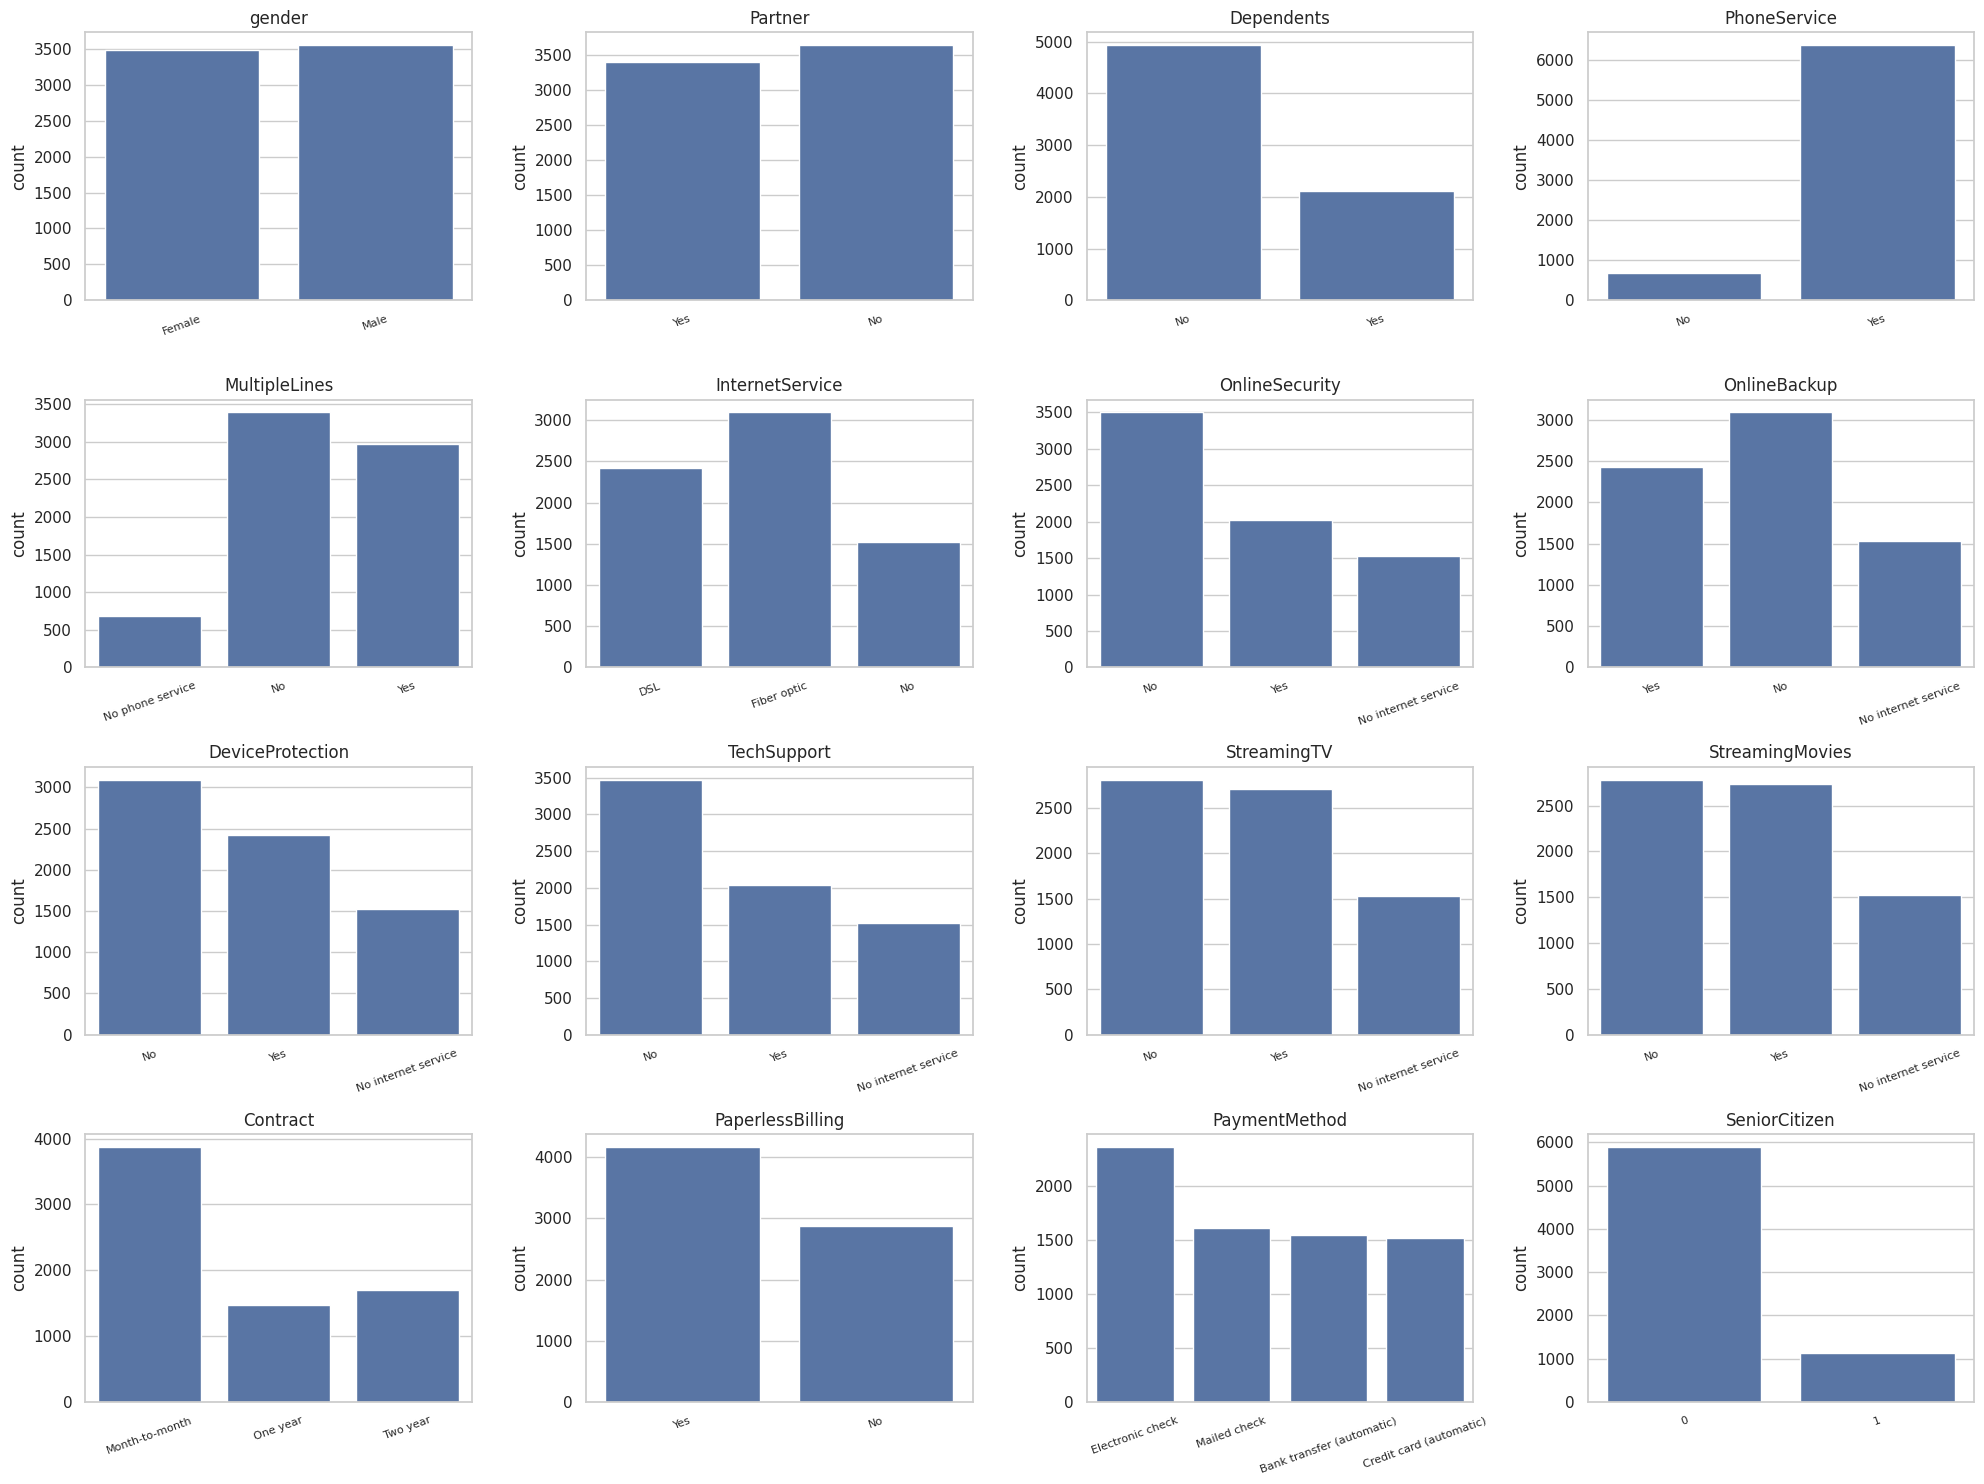

In [8]:
cat_plot_cols = CATEGORICAL + BINARY
fig, axes = plt.subplots(4, 4, figsize=(20, 15))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    sns.countplot(data=df_clean, x=col, ax=ax, color="#4C72B0")
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20, labelsize=8)
plt.tight_layout(); save_fig("03_categorical_univariate.png"); plt.show()

### 4.4 Bivariate analysis - which features relate to churn?

In [9]:
# Strength of association between each categorical feature and churn (Cramer's V from a chi-square test)
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

rows = []
for col in CATEGORICAL + BINARY:
    v, p = cramers_v(df_clean[col], df_clean[TARGET])
    rows.append({"Feature": col, "Cramers_V": v, "p_value": p})
assoc = pd.DataFrame(rows).sort_values("Cramers_V", ascending=False).reset_index(drop=True)
display(assoc.round(4))

,Feature,Cramers_V,p_value
0,Contract,0.4101,0.0000
1,OnlineSecurity,0.3474,0.0000
2,TechSupport,0.3429,0.0000
3,InternetService,0.3225,0.0000
4,PaymentMethod,0.3034,0.0000
5,OnlineBackup,0.2923,0.0000
6,DeviceProtection,0.2816,0.0000
7,StreamingMovies,0.2310,0.0000
8,StreamingTV,0.2305,0.0000
9,PaperlessBilling,0.1915,0.0000


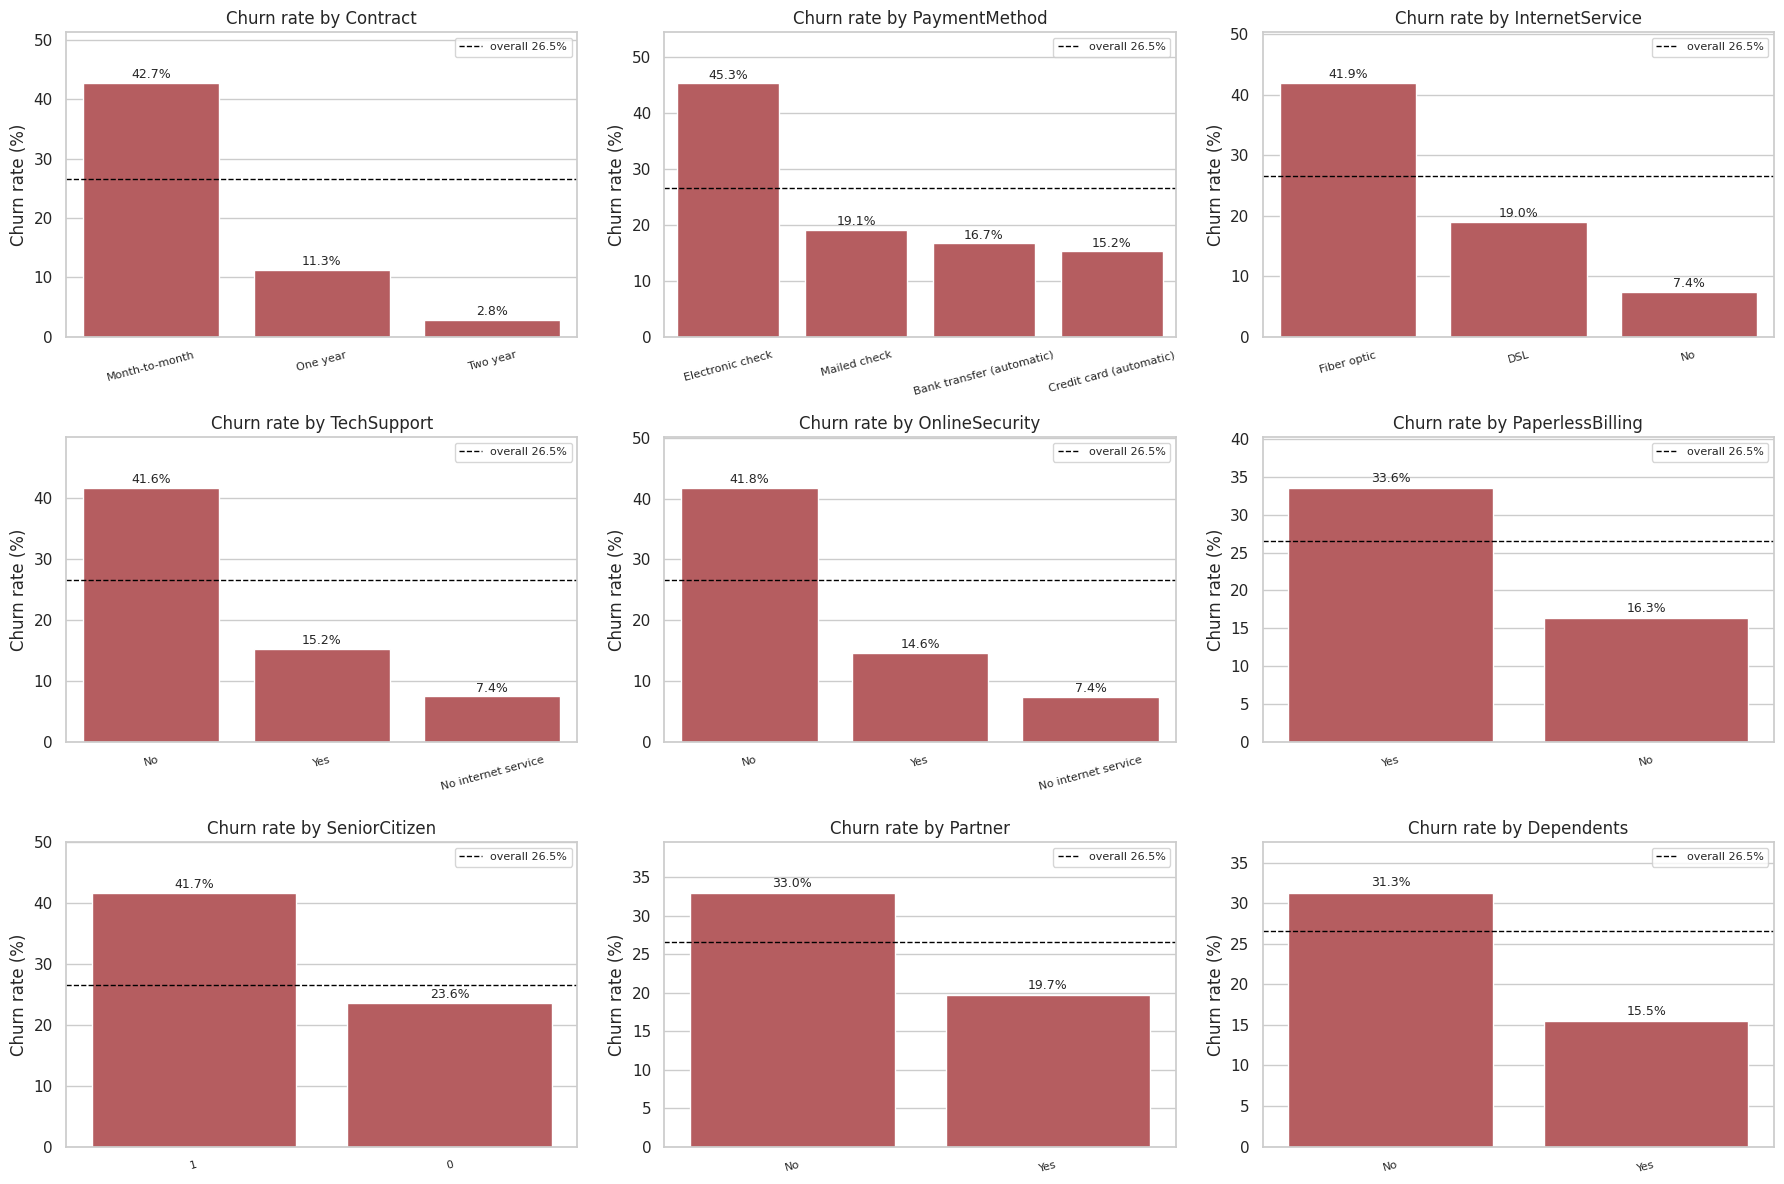

In [10]:
overall = df_clean[TARGET].mean() * 100
key_cols = ["Contract", "PaymentMethod", "InternetService", "TechSupport", "OnlineSecurity",
            "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, col in zip(axes.ravel(), key_cols):
    rate = df_clean.groupby(col)[TARGET].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#C44E52")
    ax.axhline(overall, ls="--", color="black", lw=1, label=f"overall {overall:.1f}%")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set(title=f"Churn rate by {col}", xlabel="", ylabel="Churn rate (%)", ylim=(0, max(rate.max() * 1.2, overall * 1.3)))
    ax.tick_params(axis="x", rotation=15, labelsize=8)
    ax.legend(fontsize=8)
plt.tight_layout(); save_fig("04_churn_rate_by_category.png"); plt.show()

,churn_rate_%,customers
TenureGroup,,
0-12,47.4,2186
13-24,28.7,1024
25-48,20.4,1594
49-72,9.5,2239


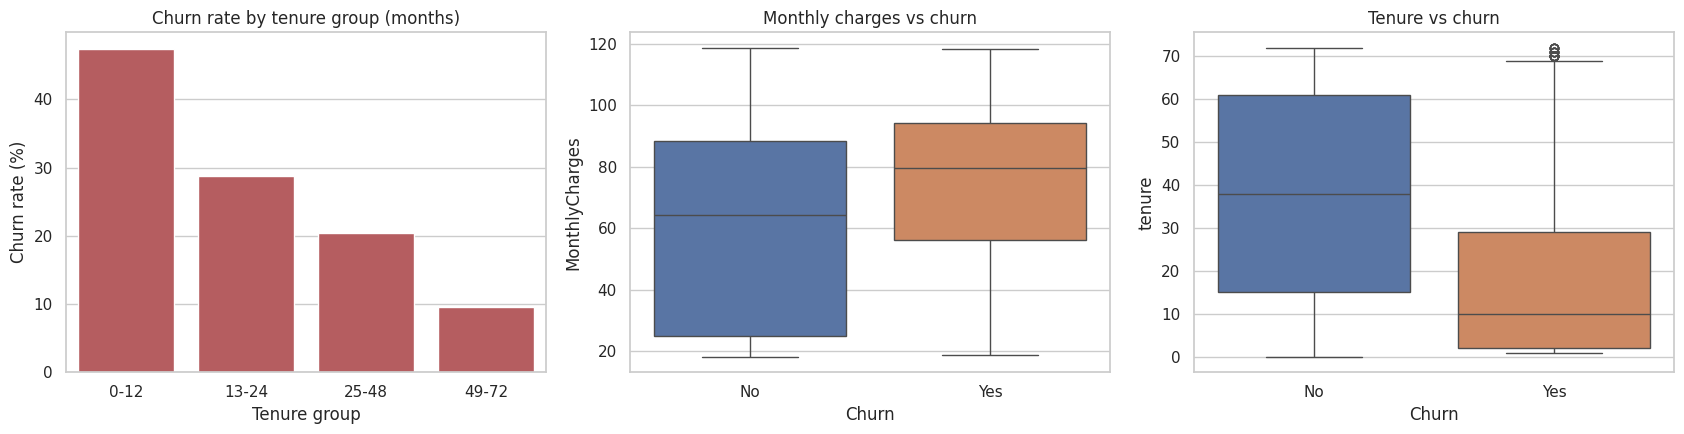

In [11]:
eda = df_clean.copy()
eda["TenureGroup"] = pd.cut(eda["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
tenure_rate = eda.groupby("TenureGroup", observed=True)[TARGET].agg(["mean", "size"])
tenure_rate["mean"] *= 100
display(tenure_rate.rename(columns={"mean": "churn_rate_%", "size": "customers"}).round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(x=tenure_rate.index.astype(str), y=tenure_rate["mean"], ax=axes[0], color="#C44E52")
axes[0].set(title="Churn rate by tenure group (months)", xlabel="Tenure group", ylabel="Churn rate (%)")
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", hue="Churn", legend=False, ax=axes[1], order=["No", "Yes"])
axes[1].set(title="Monthly charges vs churn")
sns.boxplot(data=eda, x="Churn", y="tenure", hue="Churn", legend=False, ax=axes[2], order=["No", "Yes"])
axes[2].set(title="Tenure vs churn")
plt.tight_layout(); save_fig("05_tenure_and_charges_vs_churn.png"); plt.show()

### 4.5 Multivariate view - correlation and multicollinearity

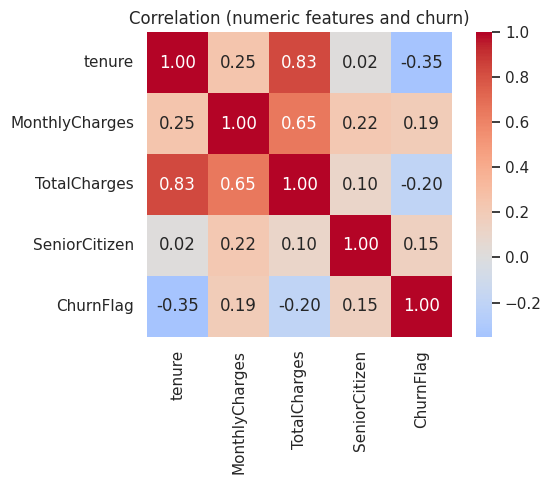

corr(TotalCharges, tenure x MonthlyCharges) = 1.0


In [12]:
corr = df_clean[NUMERIC + BINARY + [TARGET]].corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation (numeric features and churn)")
plt.tight_layout(); save_fig("06_correlation_heatmap.png"); plt.show()

# How much of TotalCharges is simply tenure x MonthlyCharges?
approx = df_clean["tenure"] * df_clean["MonthlyCharges"]
print("corr(TotalCharges, tenure x MonthlyCharges) =", round(df_clean["TotalCharges"].corr(approx), 3))

**Why this matters:** `TotalCharges` is almost exactly `tenure x MonthlyCharges`, so these three numeric features are strongly entangled. Linear models can still predict well with them, but their *individual* coefficients / SHAP signs become hard to interpret. We will come back to this in the SHAP section.

### 4.6 Segment profile (numbers used in the business recommendations)

In [13]:
def rate(mask):
    return df_clean.loc[mask, TARGET].mean() * 100, int(mask.sum())

segments = {
    "Month-to-month contract": df_clean["Contract"].eq("Month-to-month"),
    "Two-year contract": df_clean["Contract"].eq("Two year"),
    "Electronic check payment": df_clean["PaymentMethod"].eq("Electronic check"),
    "Auto-pay (bank transfer / credit card)": df_clean["PaymentMethod"].str.contains("automatic"),
    "Fiber optic internet": df_clean["InternetService"].eq("Fiber optic"),
    "No tech support (has internet)": df_clean["TechSupport"].eq("No"),
    "First-year customers (tenure <= 12)": df_clean["tenure"].le(12),
    "Senior citizens": df_clean["SeniorCitizen"].eq(1),
    "Month-to-month + fiber + e-check": df_clean["Contract"].eq("Month-to-month")
        & df_clean["InternetService"].eq("Fiber optic") & df_clean["PaymentMethod"].eq("Electronic check"),
}
seg = pd.DataFrame([(k, *rate(m)) for k, m in segments.items()], columns=["Segment", "Churn rate %", "Customers"])
display(seg.round(1).sort_values("Churn rate %", ascending=False).reset_index(drop=True))

,Segment,Churn rate %,Customers
0,Month-to-month + fiber + e-check,60.4,1307
1,First-year customers (tenure <= 12),47.4,2186
2,Electronic check payment,45.3,2365
3,Month-to-month contract,42.7,3875
4,Fiber optic internet,41.9,3096
5,Senior citizens,41.7,1142
6,No tech support (has internet),41.6,3473
7,Auto-pay (bank transfer / credit card),16.0,3066
8,Two-year contract,2.8,1695


## 5. Train / test split
Stratified 80/20 split so both parts keep the ~26.5% churn ratio. The split happens **before** any fitting (scaling, encoding, imputing), so nothing from the test set leaks into training.

In [14]:
X = df_clean[FEATURES]
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Churn rate  train: {y_train.mean():.2%}  |  test: {y_test.mean():.2%}")

Train: (5634, 19) | Test: (1409, 19)
Churn rate  train: 26.54%  |  test: 26.54%


## 6. Preprocessing pipeline
* numeric -> median imputation -> standard scaling
* binary (`SeniorCitizen`) -> passed through
* categorical -> most-frequent imputation -> one-hot encoding (`drop="if_binary"` so Yes/No columns become a single column)

A **function** builds a fresh preprocessor for every model. No fitted state is shared between pipelines, so every model is trained and cross-validated independently.

In [15]:
def build_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)),
    ])
    pre = ColumnTransformer([
        ("num", numeric_pipe, NUMERIC),
        ("bin", "passthrough", BINARY),
        ("cat", categorical_pipe, CATEGORICAL),
    ])
    pre.set_output(transform="pandas")   # keeps real feature names (needed for SHAP)
    return pre


def make_pipeline(model):
    return Pipeline([("preprocessor", build_preprocessor()), ("classifier", model)])


demo = build_preprocessor().fit(X_train)
print("Features after preprocessing:", len(demo.get_feature_names_out()))
print(list(demo.get_feature_names_out())[:8], "...")

Features after preprocessing: 40
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'bin__SeniorCitizen', 'cat__gender_Male', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__PhoneService_Yes'] ...


## 7. Model comparison with 5-fold cross-validation (training data only)

Candidates: a dummy baseline, Logistic Regression (plain and class-balanced), Random Forest, Extra Trees and Gradient Boosting.
Both Logistic Regression variants are included for a fair comparison: the tree models use class balancing, so Logistic Regression is evaluated with and without it.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Baseline (most frequent)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}

rows = []
for name, model in candidates.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        row[f"CV {metric}"] = res[f"test_{metric}"].mean()
    row["CV roc_auc std"] = res["test_roc_auc"].std()
    rows.append(row)

cv_results = pd.DataFrame(rows).sort_values("CV roc_auc", ascending=False).reset_index(drop=True)
display(cv_results.round(4))

,Model,CV roc_auc,CV pr_auc,CV precision,CV recall,CV f1,CV roc_auc std
0,Gradient Boosting,0.8482,0.6676,0.6622,0.5291,0.5880,0.0126
1,Logistic Regression,0.8462,0.6615,0.6530,0.5445,0.5932,0.0126
2,Logistic Regression (balanced),0.8460,0.6600,0.5178,0.8027,0.6293,0.0124
3,Random Forest,0.8453,0.6564,0.5578,0.7324,0.6332,0.0098
4,Extra Trees,0.8382,0.6374,0.5408,0.7559,0.6303,0.0083
5,Baseline (most frequent),0.5000,0.2654,0.0000,0.0000,0.0000,0.0000


### 7.1 Ablation: is the redundant `TotalCharges` needed?
`TotalCharges` is practically `tenure x MonthlyCharges`. We test Logistic Regression with and without each of the three numeric features (CV on training data only).

In [17]:
def lr_with_numeric(num_cols):
    pre = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
        ("bin", "passthrough", BINARY),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]), CATEGORICAL),
    ])
    return Pipeline([("preprocessor", pre), ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])


ablation = {
    "All three (tenure, MonthlyCharges, TotalCharges)": NUMERIC,
    "Drop TotalCharges": ["tenure", "MonthlyCharges"],
    "Drop MonthlyCharges": ["tenure", "TotalCharges"],
    "Tenure only": ["tenure"],
}
abl_rows = []
for label, cols in ablation.items():
    scores = cross_validate(lr_with_numeric(cols), X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)["test_score"]
    abl_rows.append({"Numeric features used": label, "CV ROC-AUC": scores.mean(), "std": scores.std()})
display(pd.DataFrame(abl_rows).round(4))

,Numeric features used,CV ROC-AUC,std
0,"All three (tenure, MonthlyCharges, TotalCharges)",0.8462,0.0126
1,Drop TotalCharges,0.8449,0.0122
2,Drop MonthlyCharges,0.8460,0.0125
3,Tenure only,0.8448,0.0121


All variants are within one standard deviation of each other, so `TotalCharges` adds almost no predictive power. We **keep** all three features (the difference is noise-level), but they are entangled, which affects how coefficients and SHAP values must be read later.

## 8. Hyper-parameter tuning
Small grids for the two most promising families (linear and boosted trees), scored by cross-validated ROC-AUC on the training set.

In [18]:
search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"classifier__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__max_depth": [2, 3],
            "classifier__subsample": [0.8, 1.0],
        },
    ),
}

tuned = {}
for name, (model, grid) in search_spaces.items():
    gs = GridSearchCV(make_pipeline(model), grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:22s} best CV ROC-AUC = {gs.best_score_:.4f}   params = { {k.split('__')[1]: v for k, v in gs.best_params_.items()} }")

Logistic Regression    best CV ROC-AUC = 0.8464   params = {'C': 3}


Gradient Boosting      best CV ROC-AUC = 0.8506   params = {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}


### Model selection rule (decided on CV only)
Pick the best CV ROC-AUC, **but prefer the simpler, more explainable Logistic Regression unless the complex model is better by more than 0.005 AUC.** For a project whose purpose is *explainable* AI, a tiny accuracy gain does not justify a black box.

In [19]:
cv_scores = {name: gs.best_score_ for name, gs in tuned.items()}
best_name = max(cv_scores, key=cv_scores.get)
if cv_scores[best_name] - cv_scores["Logistic Regression"] < 0.005:
    best_name = "Logistic Regression"

final_model = tuned[best_name].best_estimator_      # already refit on the full training set
print("Selected model:", best_name)
print(pd.Series(cv_scores).round(4).to_string())

Selected model: Logistic Regression
Logistic Regression    0.8464
Gradient Boosting      0.8506


## 9. Final evaluation on the held-out test set
This is the first time the test set is used for evaluation. The default 0.50 threshold is used here; the threshold is optimised in the next section.

In [20]:
def evaluate(pipe, X_, y_, threshold=0.5):
    proba = pipe.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_, pred),
        "Precision": precision_score(y_, pred, zero_division=0),
        "Recall": recall_score(y_, pred, zero_division=0),
        "F1": f1_score(y_, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_, proba),
        "PR-AUC": average_precision_score(y_, proba),
    }


reference = {"Baseline (most frequent)": make_pipeline(candidates["Baseline (most frequent)"]).fit(X_train, y_train)}
for name, gs in tuned.items():
    reference[f"{name} (tuned)"] = gs.best_estimator_

test_table = pd.DataFrame({name: evaluate(p, X_test, y_test) for name, p in reference.items()}).T
display(test_table.round(4))
print("Selected model:", best_name, "(chosen by cross-validation, not by this table)")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Baseline (most frequent),0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
Logistic Regression (tuned),0.8077,0.6614,0.5642,0.6089,0.8419,0.6305
Gradient Boosting (tuned),0.8041,0.6701,0.5160,0.5831,0.8465,0.6624


Selected model: Logistic Regression (chosen by cross-validation, not by this table)


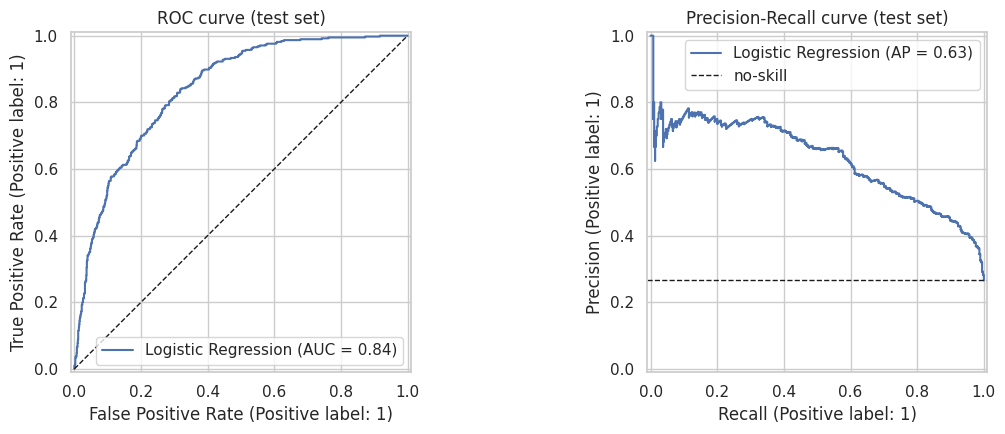

In [21]:
y_proba_test = final_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=axes[0], name=best_name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve (test set)")
PrecisionRecallDisplay.from_predictions(y_test, y_proba_test, ax=axes[1], name=best_name)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="no-skill"); axes[1].legend(); axes[1].set_title("Precision-Recall curve (test set)")
plt.tight_layout(); save_fig("07_roc_pr_curves.png"); plt.show()

## 10. Decision threshold (chosen on training data, based on business value)

The default 0.50 threshold is arbitrary. Which customers should the retention team contact? A simple expected-value model:

* contacting a customer costs one **retention offer** (`OFFER_COST`), whether or not they would have left
* a churner who is contacted is saved with probability `SUCCESS_RATE`
* every churner who is lost costs `CUSTOMER_VALUE`

These numbers are **assumptions** (relative units) - replace them with your company's real figures. The threshold is selected with **out-of-fold predictions on the training set**, so the test set stays untouched.

In [22]:
OFFER_COST = 1.0        # cost of one retention offer
CUSTOMER_VALUE = 8.0    # value lost when a churner leaves (8x the cost of an offer)
SUCCESS_RATE = 0.40     # share of contacted churners that the offer actually saves

oof_proba = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]


def business_cost(y_true, proba, t, offer=OFFER_COST, value=CUSTOMER_VALUE, success=SUCCESS_RATE):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return offer * (tp + fp) + value * (fn + tp * (1 - success)), tn, fp, fn, tp


rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (oof_proba >= t).astype(int)
    cost, tn, fp, fn, tp = business_cost(y_train, oof_proba, t)
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0),
        "Contacted": tp + fp, "Missed churners": fn, "Cost": cost,
    })
thr_table = pd.DataFrame(rows)
display(thr_table.round(3))

THRESHOLD = float(thr_table.loc[thr_table["Cost"].idxmin(), "Threshold"])
f1_best = float(thr_table.loc[thr_table["F1"].idxmax(), "Threshold"])
print(f"Cost-optimal threshold: {THRESHOLD:.2f}   |   F1-optimal threshold: {f1_best:.2f}")
print(f"Theory check: contact when p >= OFFER_COST / (SUCCESS_RATE x CUSTOMER_VALUE) = {OFFER_COST / (SUCCESS_RATE * CUSTOMER_VALUE):.2f}")

,Threshold,Precision,Recall,F1,Contacted,Missed churners,Cost
0,0.10,0.401,0.940,0.562,3507,89,10967.8
1,0.15,0.438,0.913,0.592,3115,130,10707.0
2,0.20,0.475,0.860,0.612,2705,210,10553.0
3,0.25,0.509,0.816,0.627,2399,275,10455.0
4,0.30,0.542,0.771,0.637,2126,342,10396.4
5,0.35,0.570,0.716,0.634,1878,425,10414.0
6,0.40,0.594,0.664,0.627,1673,502,10455.4
7,0.45,0.621,0.602,0.611,1449,595,10529.0
8,0.50,0.655,0.547,0.596,1249,677,10591.4
9,0.55,0.687,0.487,0.570,1060,767,10690.4


Cost-optimal threshold: 0.30   |   F1-optimal threshold: 0.30
Theory check: contact when p >= OFFER_COST / (SUCCESS_RATE x CUSTOMER_VALUE) = 0.31


**Sensitivity:** the best threshold depends on the assumptions, so we check how it moves when a lost customer is worth more or less.

In [23]:
sens = []
for value in (4, 8, 12, 20):
    costs = {round(t, 2): business_cost(y_train, oof_proba, t, value=value)[0] for t in np.arange(0.10, 0.91, 0.05)}
    sens.append({"Customer value (x offer cost)": value, "Best threshold": min(costs, key=costs.get)})
display(pd.DataFrame(sens))

,Customer value (x offer cost),Best threshold
0,4,0.65
1,8,0.30
2,12,0.20
3,20,0.15


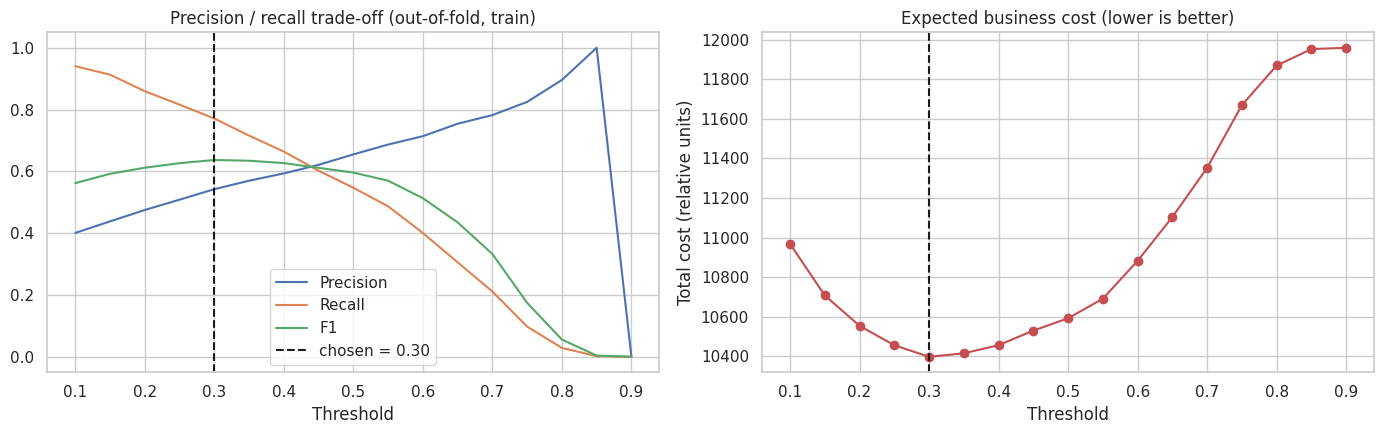

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(thr_table["Threshold"], thr_table["Precision"], label="Precision")
axes[0].plot(thr_table["Threshold"], thr_table["Recall"], label="Recall")
axes[0].plot(thr_table["Threshold"], thr_table["F1"], label="F1")
axes[0].axvline(THRESHOLD, color="k", ls="--", label=f"chosen = {THRESHOLD:.2f}")
axes[0].set(title="Precision / recall trade-off (out-of-fold, train)", xlabel="Threshold"); axes[0].legend()
axes[1].plot(thr_table["Threshold"], thr_table["Cost"], marker="o", color="#C44E52")
axes[1].axvline(THRESHOLD, color="k", ls="--")
axes[1].set(title="Expected business cost (lower is better)", xlabel="Threshold", ylabel="Total cost (relative units)")
plt.tight_layout(); save_fig("08_threshold_analysis.png"); plt.show()

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Default threshold (0.50),0.8077,0.6614,0.5642,0.6089,0.8419,0.6305
Chosen threshold (0.30),0.7488,0.5184,0.7540,0.6144,0.8419,0.6305


              precision    recall  f1-score   support

    No churn       0.89      0.75      0.81      1035
       Churn       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



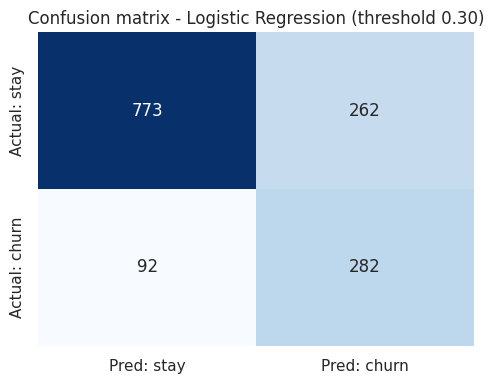

In [25]:
# One-time test-set check of the chosen threshold vs the default 0.50
compare = pd.DataFrame({
    "Default threshold (0.50)": evaluate(final_model, X_test, y_test, 0.50),
    f"Chosen threshold ({THRESHOLD:.2f})": evaluate(final_model, X_test, y_test, THRESHOLD),
}).T
display(compare.round(4))

y_pred_test = (y_proba_test >= THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_test, target_names=["No churn", "Churn"]))

cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred: stay", "Pred: churn"], yticklabels=["Actual: stay", "Actual: churn"])
plt.title(f"Confusion matrix - {best_name} (threshold {THRESHOLD:.2f})")
plt.tight_layout(); save_fig("09_confusion_matrix.png"); plt.show()

### Business view: how many churners do we catch if we only contact the riskiest customers?

In [26]:
ranked = pd.DataFrame({"proba": y_proba_test, "churn": y_test.to_numpy()}).sort_values("proba", ascending=False).reset_index(drop=True)
total_churners = ranked["churn"].sum()
gain_rows = []
for frac in (0.10, 0.20, 0.30, 0.40, 0.50):
    top = ranked.head(int(len(ranked) * frac))
    gain_rows.append({
        "Top % of customers contacted": f"{frac:.0%}",
        "Churners captured": int(top["churn"].sum()),
        "Share of all churners": top["churn"].sum() / total_churners,
        "Lift vs random": (top["churn"].mean()) / ranked["churn"].mean(),
    })
display(pd.DataFrame(gain_rows).round(3))

,Top % of customers contacted,Churners captured,Share of all churners,Lift vs random
0,10%,103,0.275,2.772
1,20%,186,0.497,2.494
2,30%,243,0.650,2.169
3,40%,290,0.775,1.941
4,50%,326,0.872,1.745


## 11. Explainable AI with SHAP

SHAP assigns every feature a contribution to each individual prediction. For the linear model the units are **log-odds of churn** (positive = pushes towards churn, negative = pushes towards staying).

In [27]:
import shap

pre_fitted = final_model.named_steps["preprocessor"]
clf = final_model.named_steps["classifier"]

X_train_t = pre_fitted.transform(X_train)     # DataFrames with readable feature names
X_test_t = pre_fitted.transform(X_test)

if hasattr(clf, "coef_"):
    background = shap.sample(X_train_t, 100, random_state=RANDOM_STATE)
    explainer = shap.LinearExplainer(clf, background)
else:
    explainer = shap.TreeExplainer(clf)

explanation = explainer(X_test_t)             # explain the whole test set
print("SHAP values:", explanation.values.shape, "| feature names attached:", explanation.feature_names is not None)

SHAP values: (1409, 40) | feature names attached: True


### 11.1 Global importance

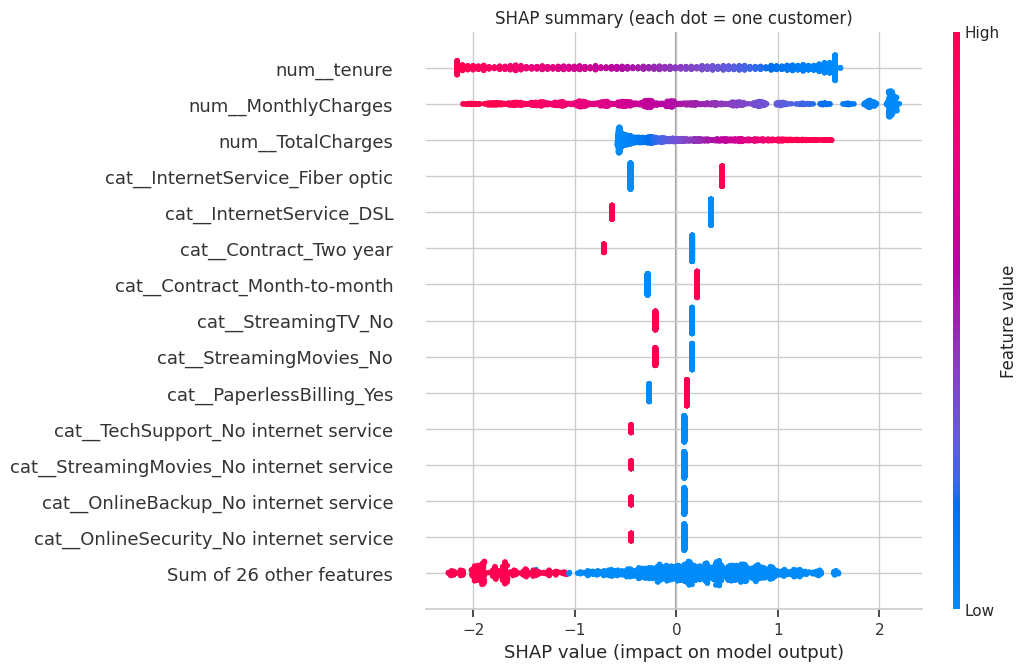

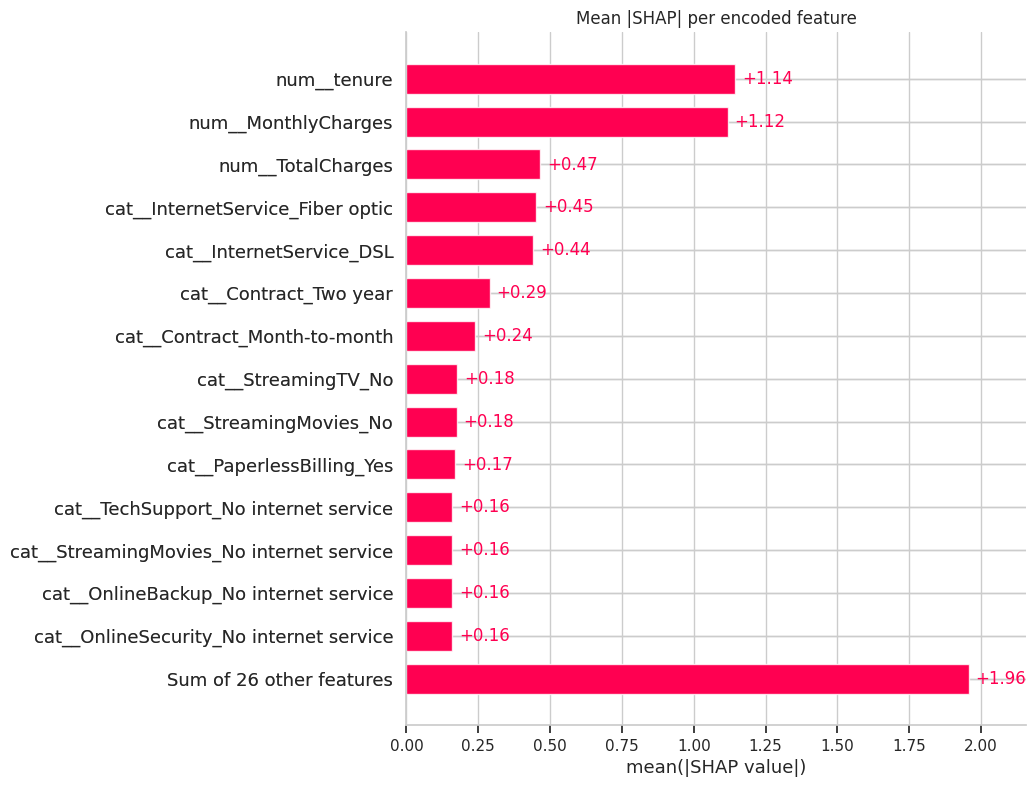

In [28]:
plt.figure()
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title("SHAP summary (each dot = one customer)")
save_fig("10_shap_beeswarm.png"); plt.show()

plt.figure()
shap.plots.bar(explanation, max_display=15, show=False)
plt.title("Mean |SHAP| per encoded feature")
save_fig("11_shap_bar.png"); plt.show()

One-hot columns such as `OnlineSecurity_No internet service`, `TechSupport_No internet service`, ... all describe the *same* fact ("no internet"), so they split that importance across several bars. Summing SHAP values back to the **original feature** gives a cleaner ranking:

,Mean |SHAP| (original feature)
tenure,1.1443
MonthlyCharges,1.1174
InternetService,0.8482
Contract,0.5132
TotalCharges,0.4654
StreamingMovies,0.3436
StreamingTV,0.3414
MultipleLines,0.2643
OnlineSecurity,0.1899
PaperlessBilling,0.1699


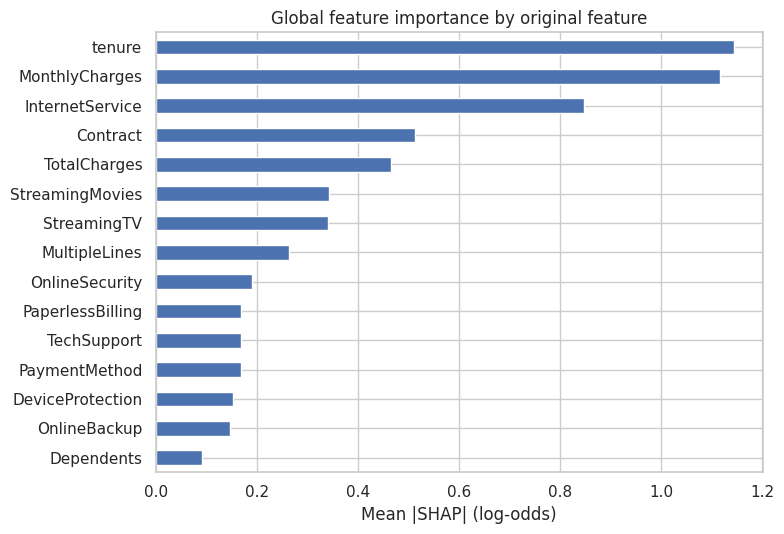

In [29]:
def original_feature(encoded_name):
    base = encoded_name.split("__", 1)[1]
    for col in CATEGORICAL:
        if base.startswith(col + "_"):
            return col
    return base


shap_df = pd.DataFrame(explanation.values, columns=X_test_t.columns)
grouped = shap_df.T.groupby(original_feature).sum().T      # additive, so summing dummies is exact
importance = grouped.abs().mean().sort_values(ascending=False)
display(importance.head(15).round(4).to_frame("Mean |SHAP| (original feature)"))

plt.figure(figsize=(8, 5.5))
importance.head(15)[::-1].plot(kind="barh", color="#4C72B0")
plt.xlabel("Mean |SHAP| (log-odds)"); plt.title("Global feature importance by original feature")
plt.tight_layout(); save_fig("12_shap_importance_original_features.png"); plt.show()

### 11.2 Direction of effect: tenure vs MonthlyCharges

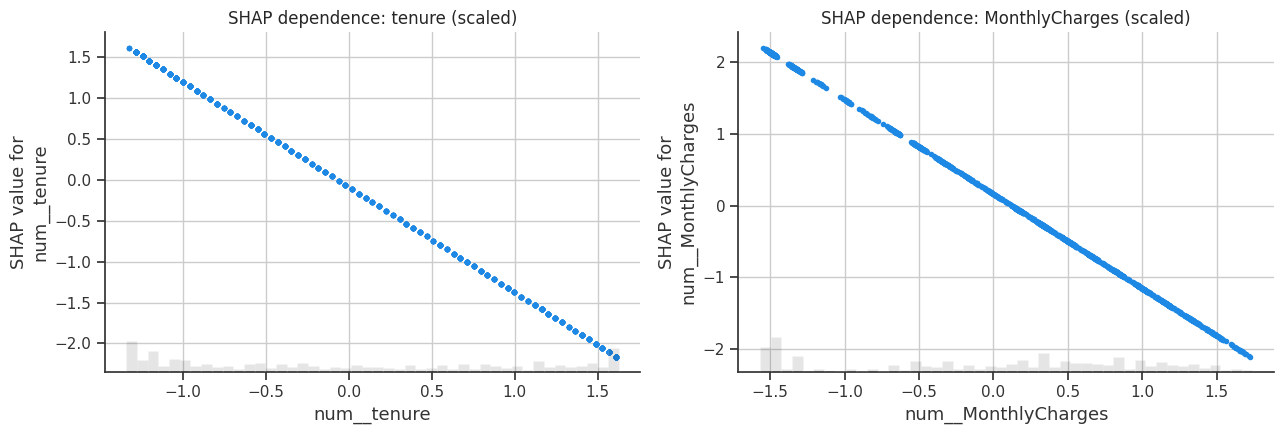

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, ["num__tenure", "num__MonthlyCharges"]):
    shap.plots.scatter(explanation[:, feat], ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {feat.split('__')[1]} (scaled)")
plt.tight_layout(); save_fig("13_shap_dependence.png"); plt.show()

### 11.3 Individual customers

HIGHEST-risk customer | churn probability = 85.4% | decision at 0.30: CHURN | actual: churned


,value
tenure,1
MonthlyCharges,95.1
TotalCharges,95.1
Contract,Month-to-month
InternetService,Fiber optic
PaymentMethod,Electronic check
TechSupport,No
PaperlessBilling,Yes


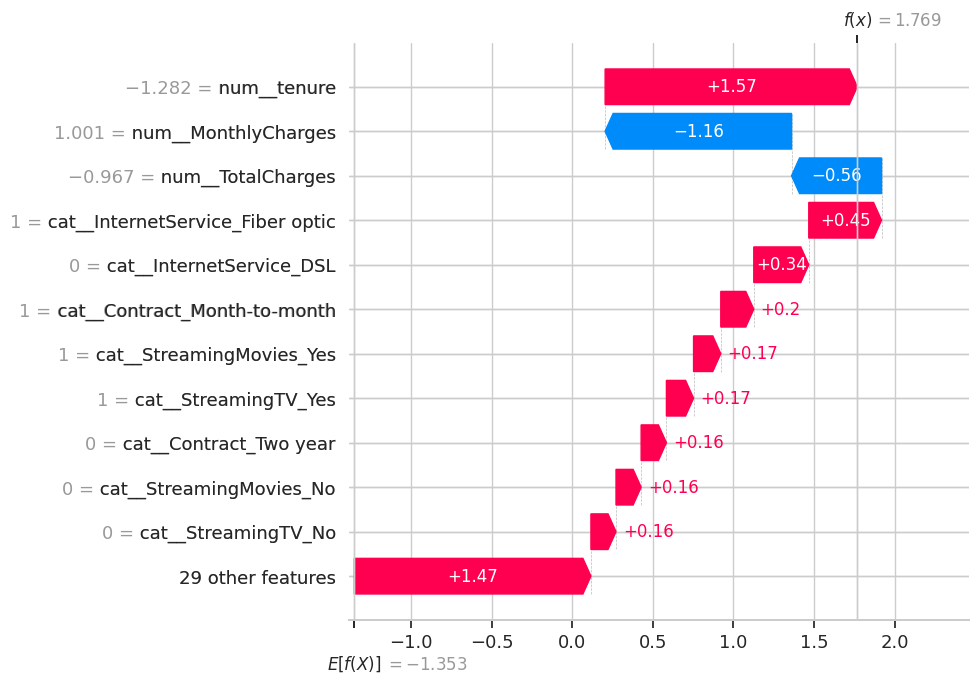

LOWEST-risk customer | churn probability = 0.2% | decision at 0.30: STAY | actual: stayed


,value
tenure,72
MonthlyCharges,19.95
TotalCharges,1322.85
Contract,Two year
InternetService,No
PaymentMethod,Bank transfer (automatic)
TechSupport,No internet service
PaperlessBilling,No


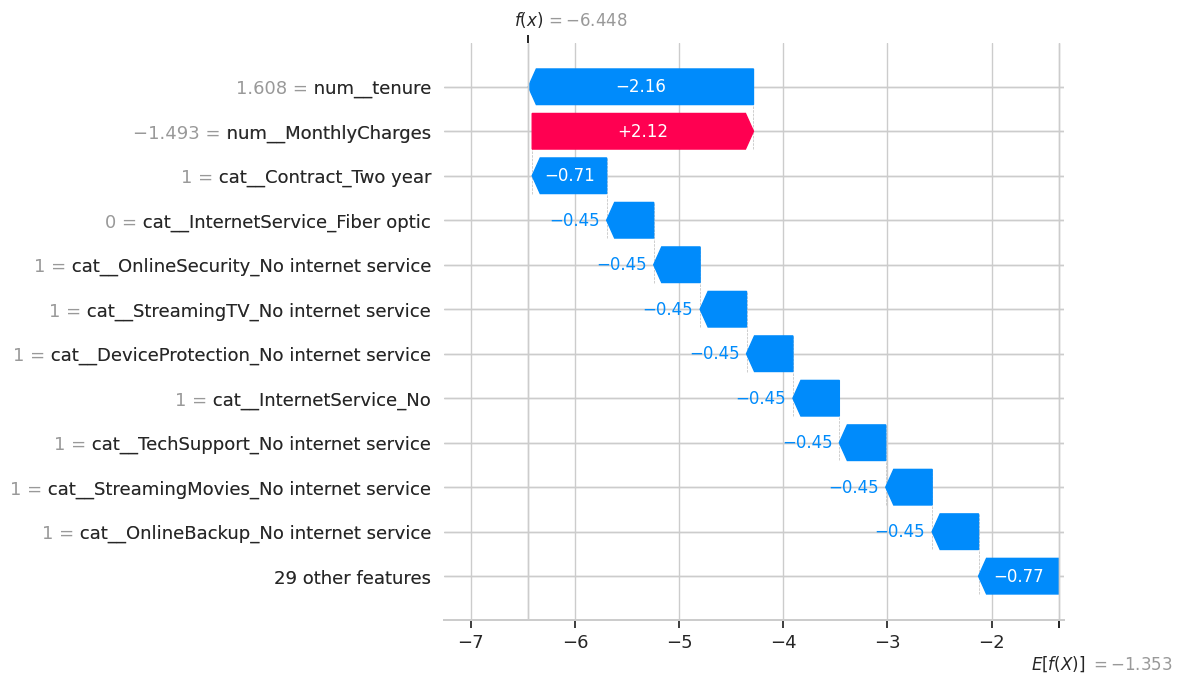

In [31]:
idx_high = int(np.argmax(y_proba_test))
idx_low = int(np.argmin(y_proba_test))
detail_cols = ["tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling"]

for label, idx in [("HIGHEST-risk", idx_high), ("LOWEST-risk", idx_low)]:
    p = y_proba_test[idx]
    print(f"{label} customer | churn probability = {p:.1%} | decision at {THRESHOLD:.2f}: {'CHURN' if p >= THRESHOLD else 'STAY'} | actual: {'churned' if y_test.iloc[idx] else 'stayed'}")
    display(X_test.iloc[[idx]][detail_cols].T.rename(columns={X_test.index[idx]: "value"}))
    plt.figure()
    shap.plots.waterfall(explanation[idx], max_display=12, show=False)
    save_fig(f"14_shap_waterfall_{label.split('-')[0].lower()}.png"); plt.show()

In [32]:
# For a linear model, SHAP = coefficient x (value - mean), so the coefficients show the direction directly.
if hasattr(clf, "coef_"):
    coefs = pd.Series(clf.coef_[0], index=X_test_t.columns)
    print("Largest churn-INCREASING coefficients (log-odds per scaled unit or per dummy):")
    print(coefs.sort_values(ascending=False).head(6).round(2).to_string())
    print("\nLargest churn-DECREASING coefficients:")
    print(coefs.sort_values().head(6).round(2).to_string())
else:
    for col in ["num__tenure", "num__MonthlyCharges", "num__TotalCharges"]:
        print(col, "corr(value, SHAP) =", round(np.corrcoef(X_test_t[col], explanation[:, col].values)[0, 1], 2))

Largest churn-INCREASING coefficients (log-odds per scaled unit or per dummy):
cat__InternetService_Fiber optic    0.90
num__TotalCharges                   0.57
cat__Contract_Month-to-month        0.49
cat__PaperlessBilling_Yes           0.37
cat__StreamingMovies_Yes            0.29
cat__StreamingTV_Yes                0.29

Largest churn-DECREASING coefficients:
num__MonthlyCharges                   -1.32
num__tenure                           -1.29
cat__InternetService_DSL              -0.98
cat__Contract_Two year                -0.87
cat__MultipleLines_No phone service   -0.58
cat__InternetService_No               -0.52


In [33]:
# Why does MonthlyCharges look "protective" here when churners actually pay MORE (see EDA box plot)?
# Refit a plain Logistic Regression with and without the service columns and compare the MonthlyCharges coefficient.
SERVICES = ["InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "MultipleLines", "PhoneService"]
OTHERS = ["Contract", "PaymentMethod", "PaperlessBilling", "Partner", "Dependents"]


def monthly_coef(cat_cols):
    pre = ColumnTransformer([
        ("n", StandardScaler(), ["tenure", "MonthlyCharges"]),
        ("c", OneHotEncoder(drop="if_binary", sparse_output=False), cat_cols),
    ])
    m = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)
    return m.named_steps["lr"].coef_[0][list(m.named_steps["pre"].get_feature_names_out()).index("n__MonthlyCharges")]


print(f"MonthlyCharges coefficient WITHOUT service columns: {monthly_coef(OTHERS):+.2f}")
print(f"MonthlyCharges coefficient WITH service columns   : {monthly_coef(OTHERS + SERVICES):+.2f}")

MonthlyCharges coefficient WITHOUT service columns: +0.70
MonthlyCharges coefficient WITH service columns   : -0.49


### 11.4 Reading the SHAP result carefully

* **Tenure is the strongest signal.** New customers are far more likely to leave; as tenure grows the SHAP value moves steadily from "pushes towards churn" to "pushes towards staying".
* **Internet service type and contract type are the next biggest drivers.** Fiber-optic customers and month-to-month customers are pushed towards churn; DSL, no-internet and two-year-contract customers are pushed towards staying.
* **Correlated features split their credit.** Dummies like `TechSupport_No internet service` and `OnlineSecurity_No internet service` all encode the same fact, so the per-column bars understate how important "internet service" really is. Summing back to the original feature (section 11.1) fixes this.
* **Be careful reading `MonthlyCharges`.** In the EDA, churners pay *more*, yet in the model a higher `MonthlyCharges` pushes *away* from churn. This is not "high price reduces churn". `MonthlyCharges` is largely determined by which services a customer has, so once the service columns are in the model the remaining `MonthlyCharges` signal means "cheaper or more expensive than the chosen services would suggest". The check above shows the coefficient changes sign when the service columns are removed.
* **Waterfall plots use scaled values.** `-1.282 = num__tenure` means the standardised tenure value; the real value is in the table printed above each plot.
* **SHAP shows association, not causation.** It explains what the model learned, not what would happen if you changed a customer's contract.

## 12. Key findings

**Who churns (EDA, full dataset, 26.5% overall churn)**

| Segment | Churn rate | Customers |
|---|---|---|
| Month-to-month contract | 42.7% | 3,875 |
| Two-year contract | 2.8% | 1,695 |
| Electronic check payment | 45.3% | 2,365 |
| Automatic payment (bank / card) | 16.0% | 3,066 |
| First year (tenure <= 12 months) | 47.4% | 2,186 |
| Tenure 49-72 months | 9.5% | 2,239 |
| Fiber optic internet | 41.9% | 3,096 |
| Internet customers without tech support | 41.6% | 3,473 |
| Month-to-month + fiber + electronic check | 60.4% | 1,307 |

`gender` and `PhoneService` show no meaningful association with churn (p > 0.3).

**How well the model predicts (test set)**

* Logistic Regression was selected: Gradient Boosting was only ~0.004 better in cross-validated ROC-AUC (0.851 vs 0.846), below the 0.005 margin needed to justify losing interpretability.
* Test ROC-AUC **0.842**, PR-AUC **0.63** (a random model would score 0.27 on PR-AUC).
* At the default 0.50 threshold: precision 66%, recall 56%. At the cost-based threshold of 0.30: **recall 75%, precision 52%, F1 0.61**.
* If the retention team can only contact the **20% riskiest customers**, they reach about **50% of all churners** (2.5x better than random); the riskiest 30% captures 65%.

## 13. Business recommendations

1. **Move month-to-month customers onto longer contracts.** This is the single strongest lever: 42.7% vs 2.8% churn. Offer discounts or perks for 1- and 2-year plans, especially in the first 12 months.
2. **Treat the first year as a retention window.** Almost half of first-year customers leave. Run a structured onboarding and check-in programme for the first 3-6 months.
3. **Push automatic payment.** Electronic-check customers churn at 45% vs 15-17% for automatic payment. Offer a small incentive to switch to bank or card auto-pay.
4. **Investigate fiber-optic service quality and pricing.** Fiber customers churn at 41.9%; check for outages, speed complaints and competitor offers in fiber areas.
5. **Bundle tech support and online security.** Customers without them churn far more; trial them free for at-risk accounts.
6. **Use the model to target outreach.** Score customers monthly, contact those above the threshold, and prioritise the top-risk decile. Re-tune the threshold with real offer costs, customer value and offer success rate.
7. **Measure with an A/B test.** Association is not causation: randomly hold out part of the high-risk group to measure whether the retention offers really reduce churn.

## 14. Save the model and metrics

In [34]:
joblib.dump(final_model, MODEL_DIR / "churn_pipeline.joblib")

final_test = evaluate(final_model, X_test, y_test, THRESHOLD)
model_card = {
    "model": best_name,
    "best_params": {k.split("__")[1]: v for k, v in tuned[best_name].best_params_.items()},
    "decision_threshold": THRESHOLD,
    "cost_assumptions": {"offer_cost": OFFER_COST, "customer_value": CUSTOMER_VALUE, "retention_success_rate": SUCCESS_RATE},
    "cv_roc_auc_train": round(float(tuned[best_name].best_score_), 4),
    "test_metrics_at_threshold": {k: round(float(v), 4) for k, v in final_test.items()},
    "features": FEATURES,
    "library_versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "shap": shap.__version__},
}
(ROOT / "models" / "model_card.json").write_text(json.dumps(model_card, indent=2))
cv_results.round(4).to_csv(ROOT / "reports" / "cv_model_comparison.csv", index=False)
thr_table.round(4).to_csv(ROOT / "reports" / "threshold_analysis.csv", index=False)
print(json.dumps(model_card["test_metrics_at_threshold"], indent=2))

{
  "Accuracy": 0.7488,
  "Precision": 0.5184,
  "Recall": 0.754,
  "F1": 0.6144,
  "ROC-AUC": 0.8419,
  "PR-AUC": 0.6305
}


In [35]:
# Reload test: the saved pipeline must reproduce the in-memory predictions exactly
reloaded = joblib.load(MODEL_DIR / "churn_pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], y_proba_test)
print("Saved pipeline reproduces predictions: OK")

Saved pipeline reproduces predictions: OK


## 15. Limitations and next steps

* **Single snapshot.** The data has no dates, so we cannot model churn over time or check for drift. A time-based split would be more realistic than a random split.
* **Business numbers are assumed.** `OFFER_COST`, `CUSTOMER_VALUE` and `SUCCESS_RATE` are placeholders; the chosen threshold moves with them (see the sensitivity table).
* **Association, not causation.** Contract type or payment method may *signal* churn without *causing* it.
* **Calibration should be re-checked on new data.** An out-of-fold calibration check on this dataset is good (`reports/figures/15_calibration_curve.png`, Brier 0.135 vs 0.195 for a no-skill model), but it must be repeated before probabilities are used as exact risk percentages in production.
* **Small gains from complex models.** Gradient Boosting was only marginally better; with more data or richer features (usage, complaints, support calls) the gap may grow.
* **Feature engineering did not help here.** Service counts, price per service and tenure flags left cross-validated ROC-AUC unchanged (0.8461-0.8464 for every variant vs 0.8464 for the current features; see `src/feature_experiment.py`). Larger gains need new data such as usage, complaints or support calls.
* **Possible next steps:** fairness check across `SeniorCitizen` and `gender`, a time-based validation, value-weighted targeting with real customer revenue, and a small Streamlit or FastAPI app that serves `models/churn_pipeline.joblib`.